In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/student-por.csv", sep=";")

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [4]:
print("Пропущенные значения:", df.isna().sum().sum())
print("Полные дубликаты:", df.duplicated().sum())

display(df.describe(include="all").T)

Пропущенные значения: 0
Полные дубликаты: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


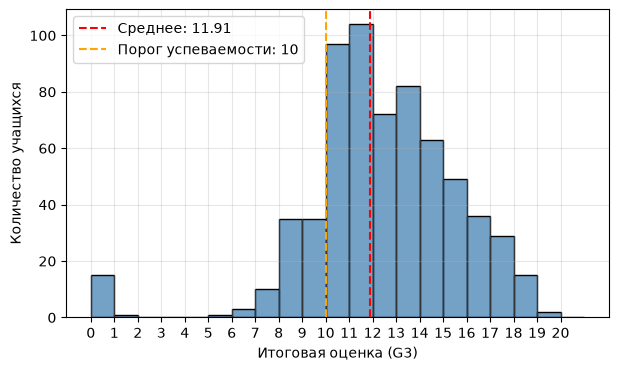

In [7]:
plt.figure(figsize=(7, 4))
sns.histplot(
    data=df,
    x="G3",
    bins=range(0, 22),
    color="steelblue"
)
plt.axvline(
    df["G3"].mean(),
    color="red",
    linestyle="--",
    label=f'Среднее: {df["G3"].mean():.2f}'
)
plt.axvline(
    10,
    color="orange",
    linestyle="--",
    label="Порог успеваемости: 10"
)
plt.xlabel("Итоговая оценка (G3)")
plt.ylabel("Количество учащихся")
plt.xticks(range(0, 21))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:
risk = df["G3"] < 10
print("Всего учащихся:", len(df))
print("Неуспевающих:", risk.sum())
print("Успевающих:", (~risk).sum())
print(f"Доля неуспевающих: {risk.mean() * 100:.2f}%")


Всего учащихся: 649
Неуспевающих: 100
Успевающих: 549
Доля неуспевающих: 15.41%


In [ ]:
cols = ["G1", "G2","studytime", "absences", "failures", "G3"]
corr = df[cols].corr()
display(corr.round(3))


,G1,G2,studytime,absences,failures,G3
G1,1.000,0.865,0.261,-0.147,-0.384,0.826
G2,0.865,1.000,0.240,-0.125,-0.386,0.919
studytime,0.261,0.240,1.000,-0.118,-0.147,0.250
absences,-0.147,-0.125,-0.118,1.000,0.123,-0.091
failures,-0.384,-0.386,-0.147,0.123,1.000,-0.393
G3,0.826,0.919,0.250,-0.091,-0.393,1.000


In [11]:
g3_corr = corr["G3"].drop("G3").sort_values(ascending=False)
display(g3_corr.round(3))


G2           0.919
G1           0.826
studytime    0.250
absences    -0.091
failures    -0.393
Name: G3, dtype: float64

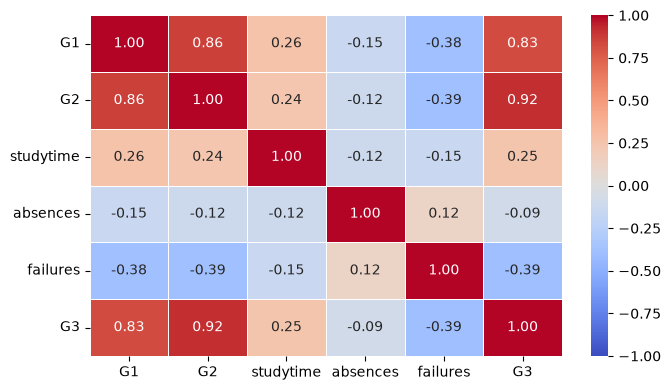

In [13]:
plt.figure(figsize=(7, 4))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.tight_layout()
plt.show()


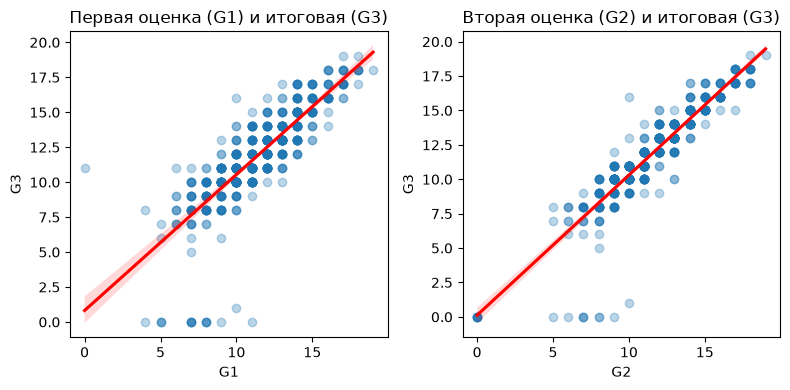

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.regplot(
    data=df,
    x="G1",
    y="G3",
    ax=axes[0],
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)
axes[0].set_title("Первая оценка (G1) и итоговая (G3)")
sns.regplot(
    data=df,
    x="G2",
    y="G3",
    ax=axes[1],
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)
axes[1].set_title("Вторая оценка (G2) и итоговая (G3)")
plt.tight_layout()
plt.show()


In [18]:
for col in ["studytime", "failures"]:
    print(f"\nПризнак: {col}")

    result = df.groupby(col)["G3"].agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )

    display(result.round(2))



Признак: studytime


,count,mean,median,std
studytime,,,,
1,212,10.84,11.0,3.22
2,305,12.09,12.0,3.24
3,97,13.23,13.0,2.50
4,35,13.06,13.0,3.04



Признак: failures


,count,mean,median,std
failures,,,,
0,549,12.51,12.0,2.83
1,70,8.64,10.0,3.44
2,16,8.81,9.5,3.21
3,14,8.07,8.5,2.79


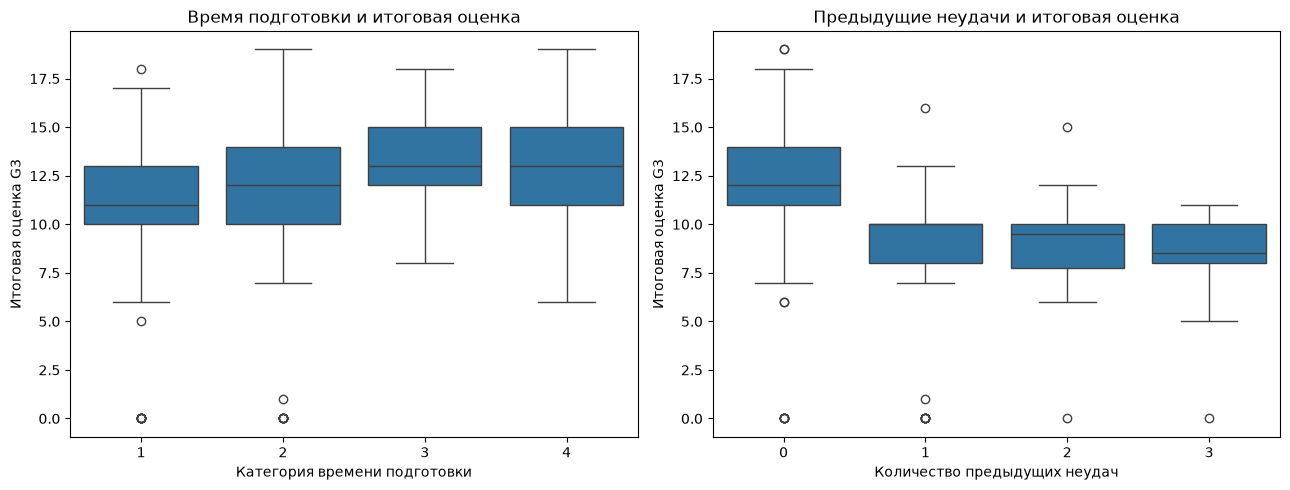

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(
    data=df,
    x="studytime",
    y="G3",
    ax=axes[0]
)
axes[0].set_title("Время подготовки и итоговая оценка")
axes[0].set_xlabel("Категория времени подготовки")
axes[0].set_ylabel("Итоговая оценка G3")

sns.boxplot(
    data=df,
    x="failures",
    y="G3",
    ax=axes[1]
)
axes[1].set_title("Предыдущие неудачи и итоговая оценка")
axes[1].set_xlabel("Количество предыдущих неудач")
axes[1].set_ylabel("Итоговая оценка G3")

plt.tight_layout()
plt.show()


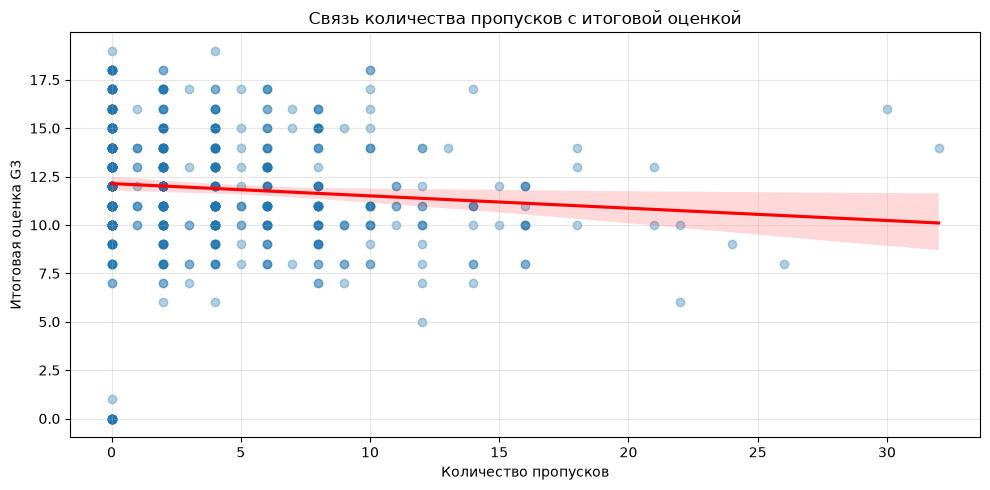

In [20]:
plt.figure(figsize=(10, 5))
sns.regplot(
    data=df,
    x="absences",
    y="G3",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)
plt.title("Связь количества пропусков с итоговой оценкой")
plt.xlabel("Количество пропусков")
plt.ylabel("Итоговая оценка G3")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:
features = ["studytime", "failures", "absences"]
spearman_corr = (
    df[features + ["G3"]]
    .corr(method="spearman")["G3"]
    .drop("G3")
    .sort_values(ascending=False)
)
display(spearman_corr.round(3))


studytime    0.275
absences    -0.159
failures    -0.448
Name: G3, dtype: float64

In [22]:
cat_cols = ["school", "sex", "higher", "internet", "schoolsup"]
for col in cat_cols:
    print(f"\nПризнак: {col}")
    result = (
        df.groupby(col)["G3"]
        .agg(count="count", mean="mean", median="median", std="std")
        .round(2)
    )
    display(result)



Признак: school


,count,mean,median,std
school,,,,
GP,423,12.58,13.0,2.63
MS,226,10.65,11.0,3.83



Признак: sex


,count,mean,median,std
sex,,,,
F,383,12.25,12.0,3.12
M,266,11.41,11.0,3.32



Признак: higher


,count,mean,median,std
higher,,,,
no,69,8.80,10.0,2.97
yes,580,12.28,12.0,3.06



Признак: internet


,count,mean,median,std
internet,,,,
no,151,11.03,11.0,3.45
yes,498,12.17,12.0,3.12



Признак: schoolsup


,count,mean,median,std
schoolsup,,,,
no,581,11.98,12.0,3.32
yes,68,11.28,11.0,2.30


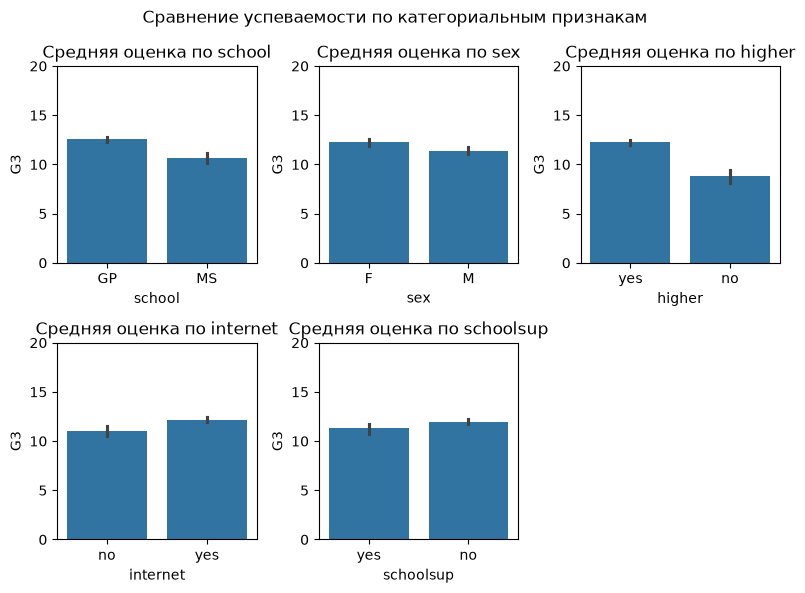

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(8, 6))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.barplot(
        data=df,
        x=col,
        y="G3",
        estimator="mean",
        errorbar=("ci", 95),
        ax=axes[i]
    )

    axes[i].set_title(f"Средняя оценка по {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylim(0, 20)
fig.delaxes(axes[-1])
plt.suptitle("Сравнение успеваемости по категориальным признакам")
plt.tight_layout()
plt.show()


In [ ]:
risk_df = df.assign(at_risk=(df["G3"] < 10).astype(int))
for col in cat_cols:
    result = (
        risk_df.groupby(col)
        .agg(
            students=("at_risk", "size"),
            at_risk_count=("at_risk", "sum"),
            risk_rate=("at_risk", "mean")
        )
    )
    result["risk_rate"] = (result["risk_rate"] * 100).round(2)
    print(f"\nРиск неуспеваемости по признаку {col}:")
    display(result)


Риск неуспеваемости по признаку school:


,students,at_risk_count,risk_rate
school,,,
GP,423,32,7.57
MS,226,68,30.09



Риск неуспеваемости по признаку sex:


,students,at_risk_count,risk_rate
sex,,,
F,383,50,13.05
M,266,50,18.80



Риск неуспеваемости по признаку higher:


,students,at_risk_count,risk_rate
higher,,,
no,69,33,47.83
yes,580,67,11.55



Риск неуспеваемости по признаку internet:


,students,at_risk_count,risk_rate
internet,,,
no,151,32,21.19
yes,498,68,13.65



Риск неуспеваемости по признаку schoolsup:


,students,at_risk_count,risk_rate
schoolsup,,,
no,581,92,15.83
yes,68,8,11.76


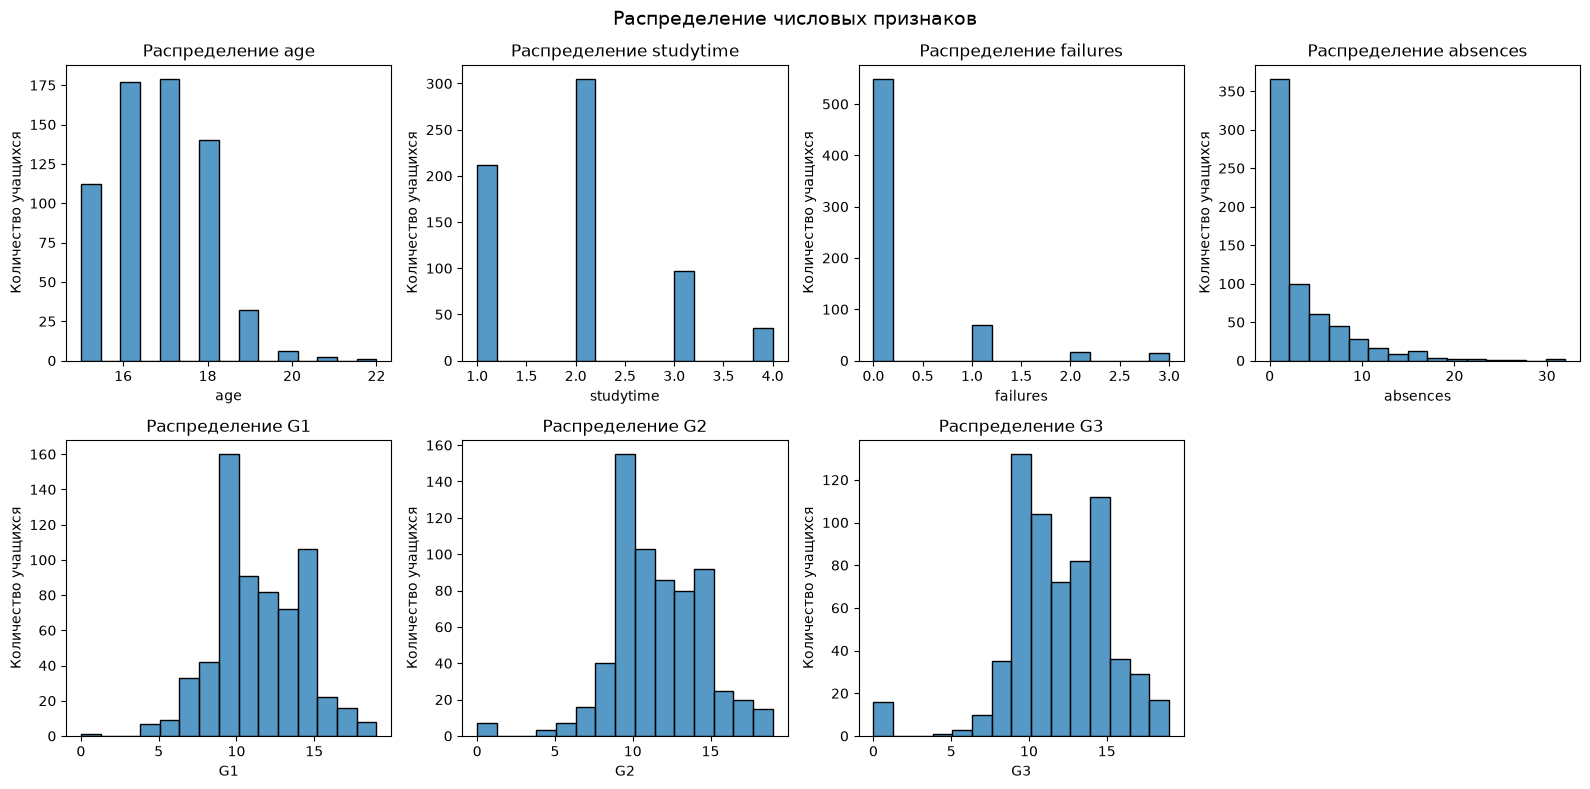

In [ ]:
num_cols = [
    "age", "studytime", "failures",
    "absences", "G1", "G2", "G3"
]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(
        df[col],
        bins=15,
        kde=False,
        ax=axes[i]
    )
    axes[i].set_title(f"Распределение {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Количество учащихся")
fig.delaxes(axes[-1])
plt.suptitle("Распределение числовых признаков", fontsize=14)
plt.tight_layout()
plt.show()


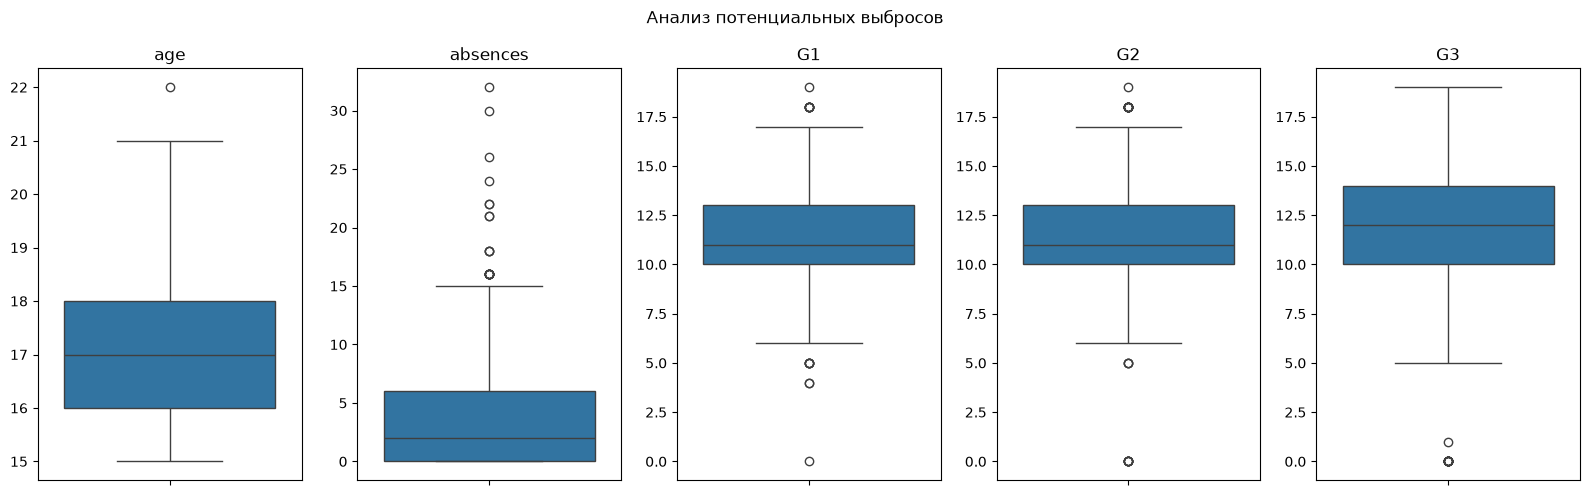

In [35]:

cols = ["age", "absences", "G1", "G2", "G3"]

fig, axes = plt.subplots(1, 5, figsize=(16, 5))

for i, col in enumerate(cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("")

plt.suptitle("Анализ потенциальных выбросов")
plt.tight_layout()
plt.show()


In [36]:
outliers = []
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outliers.append({
        "Признак": col,
        "Нижняя граница": round(lower, 2),
        "Верхняя граница": round(upper, 2),
        "Выбросы": count,
        "Доля, %": round(count / len(df) * 100, 2)
    })
outliers_df = pd.DataFrame(outliers)
display(outliers_df)


,Признак,Нижняя граница,Верхняя граница,Выбросы,"Доля, %"
0,age,13.0,21.0,1,0.15
1,absences,-9.0,15.0,21,3.24
2,G1,5.5,17.5,16,2.47
3,G2,5.5,17.5,25,3.85
4,G3,4.0,20.0,16,2.47


In [ ]:
checks = {
    "Некорректные значения G1": (~df["G1"].between(0, 20)).sum(),
    "Некорректные значения G2": (~df["G2"].between(0, 20)).sum(),
    "Некорректные значения G3": (~df["G3"].between(0, 20)).sum(),
    "Отрицательные пропуски": (df["absences"] < 0).sum(),
    "Неположительный возраст": (df["age"] <= 0).sum()
}
display(pd.Series(checks, name="Количество ошибок"))


Некорректные значения G1    0
Некорректные значения G2    0
Некорректные значения G3    0
Отрицательные пропуски      0
Неположительный возраст     0
Name: Количество ошибок, dtype: int64

In [ ]:
summary = pd.DataFrame({
    "Показатель": [
        "Количество учащихся",
        "Количество столбцов",
        "Пропущенные значения",
        "Полные дубликаты",
        "Средняя итоговая оценка G3",
        "Медианная оценка G3",
        "Минимальная оценка G3",
        "Максимальная оценка G3",
        "Учащиеся с G3 < 10",
        "Доля группы риска, %"
    ],
    "Значение": [
        len(df),
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum(),
        round(df["G3"].mean(), 2),
        df["G3"].median(),
        df["G3"].min(),
        df["G3"].max(),
        (df["G3"] < 10).sum(),
        round((df["G3"] < 10).mean() * 100, 2)
    ]
})

display(summary)


,Показатель,Значение
0,Количество учащихся,649.00
1,Количество столбцов,33.00
2,Пропущенные значения,0.00
3,Полные дубликаты,0.00
4,Средняя итоговая оценка G3,11.91
5,Медианная оценка G3,12.00
6,Минимальная оценка G3,0.00
7,Максимальная оценка G3,19.00
8,Учащиеся с G3 < 10,100.00
9,"Доля группы риска, %",15.41


In [40]:
numeric_cols = df.select_dtypes(include="number").columns
target_corr = (
    df[numeric_cols]
    .corr()["G3"]
    .drop("G3")
    .sort_values(key=abs, ascending=False)
)
display(target_corr.round(3).head(15))


G2            0.919
G1            0.826
failures     -0.393
studytime     0.250
Medu          0.240
Fedu          0.212
Dalc         -0.205
Walc         -0.177
traveltime   -0.127
freetime     -0.123
age          -0.107
health       -0.099
absences     -0.091
goout        -0.088
famrel        0.063
Name: G3, dtype: float64